## Border analysis

In [58]:
import sys
import os

# Add the project root to the system path to import local modules
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

In [59]:
from python.dualbranch.ham10000_dataset_manager import HAM10000DatasetManager
from python.utils.lesion_mask import create_simple_binary_mask, boundary_extraction
from python.utils.lesions_border_analysis import calculate_irregularity_index, preprocess_lesion
from skimage.morphology import convex_hull_image
import numpy as np
import matplotlib.pyplot as plt

In [60]:
# load the dataset manager
dataset_manager = HAM10000DatasetManager(data_dir="../../data")

# load the dataset
# dataset = dataset_manager.load_dataset(data_dir="../../data")
dataset_manager.load_cleaned_metadata()

### Get specific image from dataset, extract binary mask, and outline

In [61]:
# load specific sample image and display image id, lesions type image with outlien mask and rotated binary mask with centroid
image_id = "ISIC_0027409"

image_id, lesion_type, image = dataset_manager.get_sample_image()

binary_mask = create_simple_binary_mask(image=image)

outline = boundary_extraction(binary_mask)

### Calculate area-based irregularity index and visualize concavities

Overall Irregularity Index: 0.1804
Most Significant Feature Index: 0.0468
Concavity Areas (px): [288.0, 545.0, 12.0, 245.0, 1.0, 119.0, 9.0, 3.0, 89.0, 5.0, 1.0, 6.0, 420.0, 1.0, 8.0, 350.0]


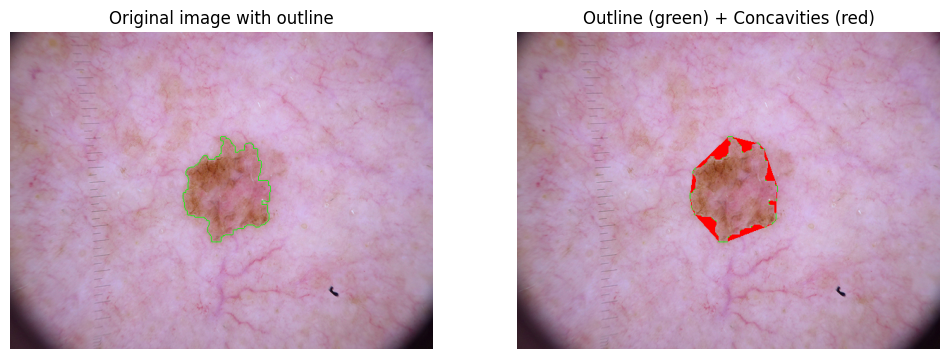

In [62]:
# Compute index from current binary_mask
result = calculate_irregularity_index(binary_mask)
print(f"Overall Irregularity Index: {result['overall_irregularity_index']:.4f}")
print(f"Most Significant Feature Index: {result['most_significant_index']:.4f}")
print(f"Concavity Areas (px): {result['feature_areas']}")

# Build visualization: convex hull vs original mask; highlight concavities
cleaned_mask = preprocess_lesion(binary_mask)
hull = convex_hull_image(cleaned_mask.astype(bool))
concavities = (hull & ~cleaned_mask.astype(bool))

overlay = image.copy()
# Ensure overlay is RGB
if overlay.ndim == 2:
    overlay = np.stack([overlay] * 3, axis=-1)

# Overlay original outline in green (uses 'outline' from previous cell)
overlay[outline > 0] = [0, 255, 0]
# Overlay concavities in red
overlay[concavities] = [255, 0, 0]

outline_overlay = image.copy()
outline_overlay[outline > 0] = [0, 255, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(outline_overlay)
axes[0].set_title("Original image with outline")
axes[0].axis('off')

axes[1].imshow(overlay)
axes[1].set_title("Outline (green) + Concavities (red)")
axes[1].axis('off')
plt.show()
